# Tutorial 1: Hydroclimatic Extreme Value Modeling (Gumbel & ETCCDI)

This tutorial demonstrates fitting extreme value distributions (Gumbel & GEV) to precipitation series and calculating ETCCDI climate indices using inundation_risk.hydroclimate.

## 1. Imports and Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from inundation_risk.hydroclimate import fit_gumbel, compute_return_periods, compute_etccdi_indices

## 2. Load Rainfall Data

In [2]:
df = pd.read_csv('../benchmarks/malang_raya/data/rainfall_annual_max.csv')
print(df.head())

   year  rx1day_max_mm
0  1981           76.3
1  1982           97.1
2  1983           70.2
3  1984           81.1
4  1985          135.9


## 3. Fit Gumbel Distribution and Compute Return Periods

In [3]:
fit = fit_gumbel(df['rx1day_max_mm'])
print('Gumbel Fit Parameters:', fit)

rps = compute_return_periods(fit, [2, 5, 10, 25, 50, 100])
print('Design Rainfall (mm):', rps)

Gumbel Fit Parameters: {'loc': 82.05654309559058, 'scale': 18.888605139790673, 'sample_mean': 92.95555555555553, 'sample_std': 23.594448071484525, 'ks_stat': 0.08653931054833741, 'ks_p_value': 0.8601507138956366, 'n_samples': 45}
Design Rainfall (mm): {'T2': 88.98, 'T5': 110.39, 'T10': 124.56, 'T25': 142.47, 'T50': 155.76, 'T100': 168.95}


## 4. Plot Return Period Curve

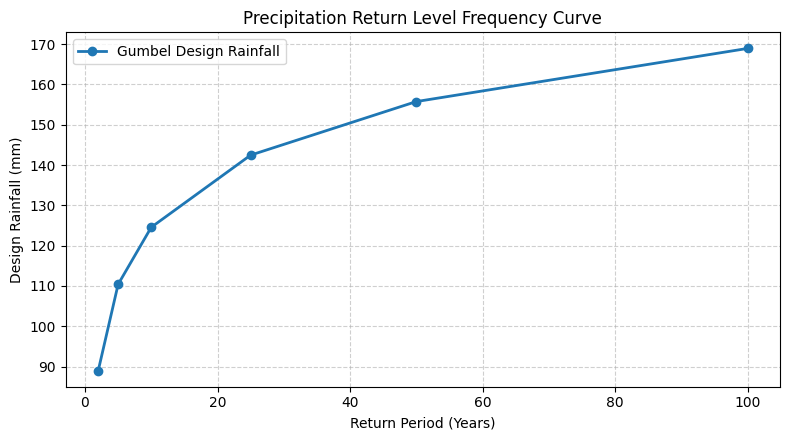

In [4]:
T_vals = [2, 5, 10, 25, 50, 100]
rain_vals = [rps[f'T{t}'] for t in T_vals]

plt.figure(figsize=(8, 4.5))
plt.plot(T_vals, rain_vals, 'o-', color='#1f77b4', linewidth=2, label='Gumbel Design Rainfall')
plt.xlabel('Return Period (Years)')
plt.ylabel('Design Rainfall (mm)')
plt.title('Precipitation Return Level Frequency Curve')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()